# Energy-preserving Bayesian operator inference - KdV 1D

Same method as problem 1, on the data of `0 - Data generation - KDV 1D.ipynb`.
Sections 1-3 differ from problem 1 only in that there is no input. Sections 4 and 5
differ in substance: the equation conserves energy, so there is no attracting set for
a certificate to describe, and the comparison rests on prediction accuracy instead.

## 0. Setup

In [1]:
import numpy as np
import time, warnings
from math import comb
from scipy.linalg import cho_factor, cho_solve, cholesky, null_space, block_diag, solve
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.stats import beta as beta_dist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import cvxpy as cp
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

D = np.load("data_KdV1D.npz")
r = int(D["r"]); L = D["train_params"].shape[0]
V = D["V"]; q_bar = D["q_bar"]; x = D["x"]; dx = float(D["dx"]); GAMMA = float(D["gamma"])
t_truth = D["t_truth"]; t_est = D["t_est"]; m_prime = t_est.size
obs_times = D["obs_times"]; Qobs = D["snapshots_compressed"]
TRAIN = D["train_params"]; TEST = D["test_params"]
TRUTH_TR = D["truth_train"]; TRUTH_TE = D["truth_test"]
T_TRAIN = float(D["t_train"][1])        # 15, read from the data rather than hard coded
T_FINAL = float(D["t_final"])           # 30

dof = 1 + r + r*(r+1)//2     # d = length of the feature vector; no input, so no B block
n   = r*dof                  # length of theta
n_c = comb(r+2, 3)           # number of EP constraints

# The quadratic term is stored compactly: only the products q_j q_k with j <= k.
PAIRS_IJ = np.triu_indices(r)
PAIRS    = list(zip(*PAIRS_IJ))

def kron_compact(q):
    """The compact Kronecker product of q with itself: the products q_j q_k, j <= k."""
    return np.outer(q, q)[PAIRS_IJ]

N_SAMP = 3000      # posterior draws
N_PRED = 60        # draws integrated for prediction
DELTA  = 0.0       # certificate margin
SEED   = 20261012

print(f"gamma = {GAMMA:g},  r = {r},  d = {dof},  n = r*d = {n},  n_c = {n_c}")
print(f"L = {L} trajectories,  m' = {m_prime} estimation times")
print(f"train on [0, {T_TRAIN:g}], predict to {T_FINAL:g}")

gamma = 0.022,  r = 10,  d = 66,  n = r*d = 660,  n_c = 220
L = 5 trajectories,  m' = 480 estimation times
train on [0, 15], predict to 30


## 1. Gaussian process state and derivative estimates

Each reduced coordinate is modelled by an independent GP with a squared-exponential
kernel and a noise term. Differentiation is linear, so the derivative posterior is
Gaussian too: with $\mathbf K=\kappa(\mathbf t,\mathbf t)+\sigma_n^2\mathbf I$,

$$
\tilde z(t') = \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\mathbf y,
\qquad
\operatorname{Var}\,\tilde z(t') = \partial_{t'}\partial_{t''}\kappa(t',t'')\big|_{t''=t'}
 - \partial_{t'}\kappa(t',\mathbf t)\,\mathbf K^{-1}\partial_{t'}\kappa(t',\mathbf t)^\top .
\tag{1}
$$

The only change from problem 1 is the kernel's length-scale window. There the training
window was $[0,1]$; here it is $[0,15]$, so the starting value and the box are scaled to
match. Section 1.1 checks what the estimates are actually worth.

In [2]:
def fit_gp(t, y, seed=1):
    # kappa(t,t') = sf2 * exp(-(t-t')^2 / (2 ell^2)) + sn2 delta_{t,t'}.
    # The lower bound on ell guards against interpolating the noise: with no floor the
    # fit can shrink ell below the spacing of the observations, follow every wiggle, and
    # return a derivative that is noise.  The floor 0.1 sits just below the spacing
    # 15/119 = 0.13, so it rules out exactly that regime.
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * RBF(2.0, (1e-1, 1e2))
         + WhiteKernel(1e-4, (1e-10, 1e0)))
    g = GaussianProcessRegressor(kernel=k, normalize_y=False,
                                 n_restarts_optimizer=3, random_state=seed)
    return g.fit(t[:, None], y)

def gp_estimates(g, t_obs, y, t_new):
    """State estimate, derivative estimate and derivative variance at t_new, eq. (1)."""
    sf2 = float(g.kernel_.k1.k1.constant_value)
    ell = float(g.kernel_.k1.k2.length_scale)
    sn2 = float(g.kernel_.k2.noise_level)

    Dm = t_new[:, None] - t_obs[None, :]        # every t_new against every t_obs
    K  = sf2*np.exp(-0.5*((t_obs[:, None] - t_obs[None, :])/ell)**2) \
         + sn2*np.eye(t_obs.size)               # noise on the observations only
    Ks = sf2*np.exp(-0.5*(Dm/ell)**2)
    Kd = Ks * (-Dm/ell**2)                      # d kappa / dt', the cross-covariance

    K_factored = cho_factor(K, lower=True)
    alpha      = cho_solve(K_factored, y)
    state      = Ks @ alpha
    derivative = Kd @ alpha

    # Var = prior slope variance sf2/ell^2 minus the explained part.  Only the
    # diagonal: the m' estimates are a linear image of m observations, so the full
    # covariance is rank deficient and each point is weighted on its own.
    K_inv_KdT = cho_solve(K_factored, Kd.T)
    explained = np.sum(Kd * K_inv_KdT.T, axis=1)
    return state, derivative, np.maximum(sf2/ell**2 - explained, 1e-12)

t0 = time.time()
STATE = np.zeros((L, r, m_prime)); DERIV = np.zeros((L, r, m_prime)); DVAR = np.zeros((L, r, m_prime))
KERN = []
for l in range(L):
    for i in range(r):
        g = fit_gp(obs_times[l], Qobs[l, i])
        STATE[l,i], DERIV[l,i], DVAR[l,i] = gp_estimates(g, obs_times[l], Qobs[l,i], t_est)
        KERN.append((l, i, g.kernel_))
print(f"{L*r} GP fits in {time.time()-t0:.1f} s")
print(f"derivative std: {np.sqrt(DVAR).min():.3e} .. {np.sqrt(DVAR).max():.3e}")

50 GP fits in 4.6 s
derivative std: 1.853e-04 .. 4.289e-01


### 1.1 How good are the derivatives?

Everything downstream is a regression onto $\tilde z$, so its accuracy caps the method.
The reference solution is available here, so the estimates can be scored against it --- a
diagnostic, not something the method is allowed to use.

Two numbers set expectations for the rest of the notebook: how fast the reduced
coordinates move, and how densely the window is sampled. The periods are measured below
and run from $1.2$ to $5$, against an observation spacing of $15/119\approx0.13$.

In [3]:
# The true reduced coordinates and their derivatives, by central differences on the
# dense output grid.  Diagnostic only: the method never sees these.
Qh_true = np.array([V.T @ (TRUTH_TR[l] - q_bar[:, None]) for l in range(L)])
dQh_true = np.gradient(Qh_true, t_truth[1]-t_truth[0], axis=2)

rel_err = np.zeros((L, r)); abs_err = np.zeros((L, r)); deriv_rms = np.zeros((L, r))
for l in range(L):
    for i in range(r):
        target = np.interp(t_est, t_truth, dQh_true[l, i])
        resid  = DERIV[l, i] - target
        abs_err[l, i]   = np.linalg.norm(resid)/np.sqrt(resid.size)      # rms error
        deriv_rms[l, i] = np.linalg.norm(target)/np.sqrt(target.size)    # rms signal
        rel_err[l, i]   = np.linalg.norm(resid)/max(np.linalg.norm(target), 1e-12)

def row(name, v, fmt="6.3f"):
    print(f"  {name:<14s}" + " ".join(format(x, fmt) for x in v))
print("per coordinate, median over the five trajectories:")
row("coordinate", np.arange(1, r+1), "6.0f")
row("rms deriv",  np.median(deriv_rms, axis=0))
row("rms error",  np.median(abs_err, axis=0))
row("rel error",  np.median(rel_err, axis=0))
print(f"\nmedian relative error {np.median(rel_err):.3f}, median rms error {np.median(abs_err):.4f}")

# Coordinate 1 needs reading with care.  Its relative error is ~1, but that is the
# ratio of two small numbers, not a bad fit: in absolute terms it is the most
# accurate coordinate of all.  See the cell below for why.
print(f"\ncoordinate 1:  rel {np.median(rel_err[:,0]):.2f}  but rms error "
      f"{np.median(abs_err[:,0]):.4f}, the smallest of the {r} coordinates "
      f"({np.argmin(np.median(abs_err,axis=0))+1 == 1})")

per coordinate, median over the five trajectories:
  coordinate         1      2      3      4      5      6      7      8      9     10
  rms deriv      0.008  0.562  0.589  0.885  0.859  0.656  0.688  0.600  0.592  0.373
  rms error      0.005  0.013  0.017  0.035  0.021  0.022  0.019  0.037  0.034  0.042
  rel error      1.001  0.023  0.030  0.040  0.026  0.033  0.024  0.062  0.057  0.113

median relative error 0.042, median rms error 0.0181

coordinate 1:  rel 1.00  but rms error 0.0052, the smallest of the 10 coordinates (True)


The first coordinate is not a dynamic mode. The basis is centred on $\bar{\mathbf q}$,
the mean over *all* trajectories, so the leading direction of the centred ensemble is the
one that separates the trajectories from each other --- parameter identity, not motion in
time. Within one trajectory it is nearly constant, and what little it does vary is at the
level of the observation noise, so no GP can recover its derivative and there is nothing
there to recover. Its relative error is $\approx1$ because the denominator is small, and
raising $r$ does not change this: the mode is still there, first.

In [4]:
train = t_truth <= T_TRAIN
print(f"{'coord':>6s} {'mean per trajectory':>44s} {'within-traj std':>16s} {'|mean|/std':>11s}")
for i in range(3):
    means = Qh_true[:, i, train].mean(axis=1)
    sd    = Qh_true[:, i, train].std(axis=1).mean()
    print(f"{i+1:6d} {np.array2string(means, precision=2, suppress_small=True):>44s} "
          f"{sd:16.4f} {np.abs(means).mean()/sd:11.1f}")

# How big is the observation noise once compressed?  Compare it with the within-
# trajectory variation of coordinate 1.
noise_rms = np.median([np.std(Qobs[l, i] - np.interp(obs_times[l], t_truth, Qh_true[l, i]))
                       for l in range(L) for i in range(r)])
print(f"\ncompressed observation noise, rms   {noise_rms:.4f}")
print(f"coordinate 1 within-trajectory std  {Qh_true[:, 0, train].std(axis=1).mean():.4f}"
      "   <- the same size: its time variation is at the noise floor")

 coord                          mean per trajectory  within-traj std  |mean|/std
     1              [-1.65  2.41 -2.23  1.45  0.01]           0.0061       255.9
     2              [ 0.    0.   -0.01 -0.03 -0.  ]           0.5244         0.0
     3              [ 0.03  0.02 -0.03  0.   -0.03]           0.4961         0.0

compressed observation noise, rms   0.0104
coordinate 1 within-trajectory std  0.0061   <- the same size: its time variation is at the noise floor


In [5]:
# How fast do the reduced coordinates actually move?  The dominant period of each
# coordinate, from the peak of its spectrum on the training window.  This is what the
# observation spacing has to resolve, and it is the quantity to compare across problems.
def dominant_period(y, dt):
    y = y - y.mean()
    F = np.abs(np.fft.rfft(y*np.hanning(y.size)))
    f = np.fft.rfftfreq(y.size, dt); F[0] = 0.0
    return 1.0/f[F.argmax()]

dt_truth = t_truth[1] - t_truth[0]
PERIODS = np.median([[dominant_period(Qh_true[l, i, train], dt_truth) for i in range(r)]
                     for l in range(L)], axis=0)
spacing = T_TRAIN/(obs_times.shape[1] - 1)
print("dominant period per coordinate:",
      np.array2string(PERIODS, precision=2, suppress_small=True))
print(f"observation spacing {spacing:.3f} with m = {obs_times.shape[1]}")
print(f"samples per oscillation: {PERIODS.min()/spacing:.0f} on the fastest coordinate, "
      f"{PERIODS.max()/spacing:.0f} on the slowest")
print("\nFor reference, problem 1 observed its window at 15 to 29 samples per oscillation.")


dominant period per coordinate: [5.02 5.02 5.02 2.15 2.15 3.01 3.01 1.51 1.51 1.16]
observation spacing 0.126 with m = 120
samples per oscillation: 9 on the fastest coordinate, 40 on the slowest

For reference, problem 1 observed its window at 15 to 29 samples per oscillation.


In [6]:
# Is the derivative error a GP problem or a sampling problem?  Re-observe the stored
# reference solution at coarser spacings and at the nominal one, with the same noise
# model, and refit.  Diagnostic only: the method itself only ever sees the m snapshots
# it was given.
XI = float(D["xi"])                 # the level the data were generated at
print(f"{'m':>5s} {'spacing':>9s} {'samp/osc':>9s} {'median rel err':>15s} {'median rms err':>15s}")
for m_try in sorted({30, 60, obs_times.shape[1]}):
    rng_m = np.random.default_rng(0)
    rel, rms = [], []
    for l in range(L):
        t_o = np.sort(rng_m.uniform(0, T_TRAIN, m_try)); t_o[0], t_o[-1] = 0.0, T_TRAIN
        clean = np.array([np.interp(t_o, t_truth, Qh_true[l, i]) for i in range(r)])
        full  = q_bar[:, None] + V @ clean
        noisy = full.copy(); body = full[:, 1:]
        noisy[:, 1:] = body + XI*np.abs(body)*rng_m.standard_normal(body.shape)
        Qn = V.T @ (noisy - q_bar[:, None])
        for i in range(r):
            _, d, _ = gp_estimates(fit_gp(t_o, Qn[i]), t_o, Qn[i], t_est)
            tgt = np.interp(t_est, t_truth, dQh_true[l, i])
            rel.append(np.linalg.norm(d-tgt)/max(np.linalg.norm(tgt), 1e-12))
            rms.append(np.linalg.norm(d-tgt)/np.sqrt(d.size))
    print(f"{m_try:5d} {T_TRAIN/(m_try-1):9.3f} "
          f"{PERIODS.min()/(T_TRAIN/(m_try-1)):9.1f} {np.median(rel):15.3f} {np.median(rms):15.4f}")
print("\n-> the error is set by how densely the window is sampled, not by the GP.  At"
      "\n   m = 30 the fastest coordinates get fewer than two samples per oscillation, which"
      "\n   is aliasing rather than sparse sampling; the nominal m resolves them.")

    m   spacing  samp/osc  median rel err  median rms err
   30     0.517       2.2           0.356          0.0843
   60     0.254       4.6           0.095          0.0342
  120     0.126       9.2           0.041          0.0193

-> the error is set by how densely the window is sampled, not by the GP.  At
   m = 30 the fastest coordinates get fewer than two samples per oscillation, which
   is aliasing rather than sparse sampling; the nominal m resolves them.


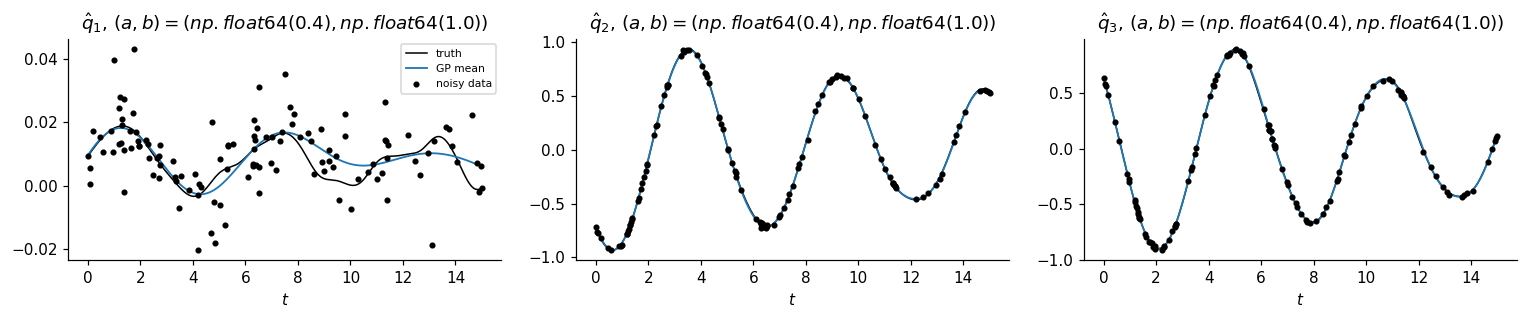

In [7]:
# The first three coordinates of one trajectory: data, GP state, and the truth.
l_show = 4
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for i, ax in enumerate(axes):
    ax.plot(t_truth[train], Qh_true[l_show, i, train], "k", lw=1, label="truth")
    ax.plot(t_est, STATE[l_show, i], "C0", lw=1.2, label="GP mean")
    ax.plot(obs_times[l_show], Qobs[l_show, i], "ko", ms=3, label="noisy data")
    ax.set(xlabel="$t$", title=rf"$\hat q_{{{i+1}}}$, $(a,b)={tuple(TRAIN[l_show])}$")
    if i == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. The operator posterior

With feature vector $\mathbf d(\hat{\mathbf q})=[1;\ \hat{\mathbf q};\ \hat{\mathbf q}\,\hat\otimes\,\hat{\mathbf q}]\in\mathbb R^{d}$
--- no input block here --- and $\widetilde{\mathbf D}$ the matrix of features at the
estimation times of all trajectories, each row $\hat{\mathbf o}_i$ has the Gaussian posterior

$$
\hat{\mathbf o}_i\mid\text{data}\sim\mathcal N(\boldsymbol\mu_i,\boldsymbol\Sigma_i),
\qquad
\boldsymbol\Sigma_i=\bigl(\widetilde{\mathbf D}^\top\mathbf W_i\widetilde{\mathbf D}+\boldsymbol\Gamma_i^2\bigr)^{-1},
\qquad
\boldsymbol\mu_i=\boldsymbol\Sigma_i\widetilde{\mathbf D}^\top\mathbf W_i\tilde{\mathbf z}_i .
\tag{2}
$$

In [8]:
def features(q):
    """The feature vector d(q) = [1; q; q (x) q].  No input term in this problem."""
    return np.concatenate(([1.0], q, kron_compact(q)))

Dtil = np.zeros((L*m_prime, dof))
for l in range(L):
    for k in range(m_prime):
        Dtil[l*m_prime + k] = features(STATE[l, :, k])

# z~ = Phi theta + e, e ~ N(0, W^-1), with Phi = blkdiag(D~, ..., D~).
zvec = np.concatenate([DERIV[:, i, :].reshape(-1) for i in range(r)])
wvec = np.concatenate([1.0/DVAR[:, i, :].reshape(-1) for i in range(r)])
Nobs = zvec.size
Phi  = block_diag(*([Dtil]*r))

DWD = np.zeros((r, dof, dof)); DWz = np.zeros((r, dof))
for i in range(r):
    for l in range(L):
        Dl = Dtil[l*m_prime:(l+1)*m_prime]
        wl = 1.0/DVAR[l, i]
        DWD[i] += Dl.T @ (wl[:, None]*Dl)
        DWz[i] += Dl.T @ (wl*DERIV[l, i])
print(f"D~ {Dtil.shape}, cond {np.linalg.cond(Dtil):.2e}")
print(f"Phi {Phi.shape},  N = {Nobs} observations,  n = {n} unknowns")

D~ (2400, 66), cond 2.70e+02
Phi (24000, 660),  N = 24000 observations,  n = 660 unknowns


## 3. Energy preservation

### 3.1 The constraint

$\widehat{\mathbf H}$ is energy preserving iff $H_{ijk}+H_{jik}+H_{kij}=0$ for all $i,j,k$.
Collected into a matrix acting on $\boldsymbol\theta=[\hat{\mathbf o}_1;\dots;\hat{\mathbf o}_r]$,

$$
\widehat{\mathbf H}\in\mathcal H_{\mathrm{EP}}\iff \mathbf C\boldsymbol\theta=\mathbf 0,
\qquad \mathbf C\in\mathbb R^{n_c\times n},\quad \operatorname{rank}\mathbf C=n_c .
\tag{3}
$$

In [9]:
def index_of_h(i, j, k):
    """Where the compact coefficient h_{i,jk} sits inside theta.

    Row i starts at i*dof and is laid out as [c_i, A_i (r), H_i (compact)], so the
    quadratic part starts at i*dof + 1 + r.  h_{i,jk} = h_{i,kj}, so the pair is
    sorted before being looked up.
    """
    pair = (min(j, k), max(j, k))
    return i*dof + 1 + r + PAIRS.index(pair)

rows = []
for a in range(r):                                   # q_a^3
    row = np.zeros(n); row[index_of_h(a, a, a)] += 1.0; rows.append(row)
for a in range(r):
    for c in range(a+1, r):
        row = np.zeros(n)                            # q_a^2 q_c
        row[index_of_h(a, a, c)] += 1.0; row[index_of_h(c, a, a)] += 1.0; rows.append(row)
        row = np.zeros(n)                            # q_a q_c^2
        row[index_of_h(a, c, c)] += 1.0; row[index_of_h(c, a, c)] += 1.0; rows.append(row)
for a in range(r):                                   # q_a q_b q_c, all distinct
    for b in range(a+1, r):
        for c in range(b+1, r):
            row = np.zeros(n)
            row[index_of_h(a, b, c)] += 1.0
            row[index_of_h(b, a, c)] += 1.0
            row[index_of_h(c, a, b)] += 1.0
            rows.append(row)

Cmat = np.array(rows)
print(f"C: {Cmat.shape},  expected n_c = {n_c},  rank = {np.linalg.matrix_rank(Cmat)}")

Tker = null_space(Cmat)
print(f"ker C: {Tker.shape} (expected {n - n_c}),  ||C T|| = {np.abs(Cmat@Tker).max():.2e}")

C: (220, 660),  expected n_c = 220,  rank = 220
ker C: (660, 440) (expected 440),  ||C T|| = 4.44e-16


### 3.2 Prior scales by marginal likelihood

The prior is $\hat{\mathbf o}_i\sim\mathcal N(\mathbf 0,\boldsymbol\Gamma_i^{-2})$ with one
scale per operator block ($\hat{\mathbf c},\widehat{\mathbf A},\widehat{\mathbf H}$),
chosen by maximising the closed-form log evidence

$$
\log p(\tilde{\mathbf z})
 = -\tfrac N2\log2\pi + \tfrac12\log|\mathbf W| + \tfrac12\log|\mathbf P_0|
 - \tfrac12\log|\mathbf P|
 - \tfrac12\bigl(\tilde{\mathbf z}^\top\mathbf W\tilde{\mathbf z}-\boldsymbol\mu^\top\mathbf P\boldsymbol\mu\bigr),
\tag{4}
$$

with $\mathbf P=\boldsymbol\Phi^\top\mathbf W\boldsymbol\Phi+\mathbf P_0$. The scales are
selected under the *constrained* model, so (4) is applied with
$\boldsymbol\Phi\to\boldsymbol\Phi\mathbf T$ and
$\mathbf P_0=\mathbf T^\top\operatorname{diag}(\boldsymbol\gamma^2)\mathbf T$.

In [10]:
# Which operator block each component of theta belongs to: 0 = c, 1 = A, 2 = H.
block_of = np.tile(np.concatenate(([0], np.full(r, 1), np.full(r*(r+1)//2, 2))), r)

PhiT        = Phi @ Tker
PhiT_W_PhiT = PhiT.T @ (wvec[:, None]*PhiT)
PhiT_W_z    = PhiT.T @ (wvec*zvec)
z_W_z       = zvec @ (wvec*zvec)
logdet_W    = np.sum(np.log(wvec))

# P0 = T' diag(gamma^2) T is linear in the three gamma_b^2, so the three matrices it
# is built from are formed once instead of inside every evidence evaluation.
M_block = [Tker[block_of == b].T @ Tker[block_of == b] for b in (0, 1, 2)]

def log_evidence(gam):
    """Eq. (4) in the coordinates of ker C."""
    P0 = sum((gam[b]**2)*M_block[b] for b in range(3))
    P  = PhiT_W_PhiT + P0
    sign0, logdet_P0 = np.linalg.slogdet(P0)
    signP, logdet_P  = np.linalg.slogdet(P)
    if sign0 <= 0 or signP <= 0:
        return -1e12
    mu_z = solve(P, PhiT_W_z, assume_a="pos")
    return (-0.5*Nobs*np.log(2*np.pi) + 0.5*logdet_W + 0.5*logdet_P0 - 0.5*logdet_P
            - 0.5*(z_W_z - mu_z @ (P @ mu_z)))

t0 = time.time(); best = None
for log_gamma_0 in ([-2.]*3, [0.]*3, [2.]*3):
    result = minimize(lambda lg: -log_evidence(np.exp(lg)), log_gamma_0,
                      method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best is None or result.fun < best.fun:
        best = result
gamma = np.exp(best.x)
print(f"evidence maximised in {time.time()-t0:.1f} s,  log p(z~) = {-best.fun:.2f}")
for name, g in zip(["c", "A", "H"], gamma):
    print(f"   gamma_{name} = {g:.4f}")

evidence maximised in 2.0 s,  log p(z~) = -65767.02
   gamma_c = 37.1665
   gamma_A = 1.3715
   gamma_H = 7.3371


In [11]:
# --- row posteriors, eq. (2) ---
def prior_scales(gam):
    g_c, g_A, g_H = gam
    one_row = np.concatenate(([g_c], np.full(r, g_A), np.full(r*(r+1)//2, g_H)))
    return np.tile(one_row, r)

gvec = prior_scales(gamma)
Sig = np.zeros((n, n)); mu = np.zeros(n); Lchol = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    Sig[block, block] = Sig_i
    mu[block] = Sig_i @ DWz[i]
    Lchol.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))
print(f"unconstrained posterior: ||C mu|| = {np.linalg.norm(Cmat@mu):.4e}")

unconstrained posterior: ||C mu|| = 2.6385e+00


### 3.3 Conditioning on the constraint, and sampling

The constraint is a noise-free measurement $\mathbf C\boldsymbol\theta=\mathbf 0$:

$$
\mathbf K=\boldsymbol\Sigma\mathbf C^\top(\mathbf C\boldsymbol\Sigma\mathbf C^\top)^{-1},
\qquad
\boldsymbol\mu_c=\boldsymbol\mu-\mathbf K\mathbf C\boldsymbol\mu,
\qquad
\boldsymbol\Sigma_c=\boldsymbol\Sigma-\mathbf K\mathbf C\boldsymbol\Sigma ,
\tag{5}
$$

and a draw is corrected by the same fixed linear map,
$\boldsymbol\theta_c=\boldsymbol\theta-\mathbf K\mathbf C\boldsymbol\theta$.

In [12]:
Sig_Ct     = Sig @ Cmat.T
innovation = Cmat @ Sig_Ct
Kg         = solve(innovation, Sig_Ct.T, assume_a="pos").T
mu_c  = mu  - Kg @ (Cmat @ mu)
Sig_c = Sig - Kg @ Sig_Ct.T

reduced_precision = Tker.T @ np.linalg.inv(Sig) @ Tker
Sig_from_kernel   = Tker @ np.linalg.inv(reduced_precision) @ Tker.T
print(f"||C mu_c||  = {np.linalg.norm(Cmat@mu_c):.3e}")
print(f"max |C Sig_c| = {np.abs(Cmat@Sig_c).max():.3e}")
print(f"max |Sig_c - T(T'Sig^-1T)^-1T'| = {np.abs(Sig_c-Sig_from_kernel).max():.3e}   (equivalence)")

def draw(rng):
    """One draw of the constrained posterior."""
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu[block] + Lchol[i] @ rng.standard_normal(dof)
    return theta - Kg @ (Cmat @ theta)

def unpack(theta):
    """Split theta into (c_hat, A_hat, H_hat), the last compact."""
    O = theta.reshape(r, dof)
    return O[:, 0], O[:, 1:1+r], O[:, 1+r:dof]

rng = np.random.default_rng(SEED)
violation = np.array([np.linalg.norm(Cmat @ draw(rng)) for _ in range(200)])
print(f"\n||C theta_c|| over 200 draws: max {violation.max():.3e}   (exactly EP, draw by draw)")

||C mu_c||  = 1.603e-15
max |C Sig_c| = 8.674e-19
max |Sig_c - T(T'Sig^-1T)^-1T'| = 6.745e-13   (equivalence)

||C theta_c|| over 200 draws: max 1.778e-15   (exactly EP, draw by draw)


## 4. Stability certificates

Reported for completeness, and expected to say nothing. With $\widehat{\mathbf H}$ energy
preserving, $V=\tfrac12\|\hat{\mathbf q}\|^2$ gives
$\dot V\le-\alpha\|\hat{\mathbf q}\|^2+K\|\hat{\mathbf q}\|$ with
$\alpha=-\lambda_{\max}(\operatorname{sym}\widehat{\mathbf A})$, and measuring the energy
about a centre $\mathbf m$ gives the best rate $\alpha^\star=-t^\star$ from

$$
t^\star=\min_{t,\ \mathbf m}\ t
\quad\text{s.t.}\quad
\operatorname{sym}\widehat{\mathbf A}+\operatorname{sym}\mathbf L_{\mathbf m}\preceq t\,\mathbf I ,
\qquad \mathbf L_{\mathbf m}=2\widehat{\mathbf H}(\mathbf m\otimes\mathbf I).
\tag{6}
$$

What a positive $\alpha^\star$ buys is a ball the trajectory is drawn into. The KdV
equation conserves $E$, so it has no such ball: it is bounded by its initial energy, not
by an attractor. A draw that certifies has therefore acquired a dissipative linear part the
equation does not have, and the certified radius describes that draw, not the physics.

Nor is certifying a coin toss. It asks all $r$ eigenvalues of
$\operatorname{sym}\widehat{\mathbf A}$ to be non-positive at once, and the intrusive ROM
already has four of its ten positive, spread as widely as the six negative ones. We expect
$\hat p_\delta\approx0$ and read the accuracy of section 5 instead.

In [13]:
def expand_H(H_hat):
    """The full H in R^{r x r^2}, from the compact coefficients h_{i,jk}.

    An off-diagonal coefficient is split between the two columns j*r+k and k*r+j, so
    that H (q (x) q) reproduces the compact product and H is symmetric in its last two
    indices --- which is what lets the two cross terms of the shift combine into L_m.
    """
    H = np.zeros((r, r*r))
    for col, (j, k) in enumerate(PAIRS):
        if j == k:
            H[:, j*r + j] = H_hat[:, col]
        else:
            H[:, j*r + k] = H_hat[:, col]/2
            H[:, k*r + j] = H_hat[:, col]/2
    return H

def L_of_m(H, m):
    """L_m = 2 H (m (x) I_r).  m[:, None] matters: with a 1-D m, np.kron would
    broadcast it to a row and return the transpose of the intended matrix."""
    return 2 * H @ np.kron(m[:, None], np.eye(r))

def shift_matrices(H):
    """The r symmetric matrices S_j with sym(L_m) = sum_j m_j S_j."""
    return np.array([0.5*(L_of_m(H, e) + L_of_m(H, e).T) for e in np.eye(r)])

def certify(theta):
    """Return (alpha, alpha_star, m, g) for one draw.  m = 0 is feasible in (6), so
    alpha_star >= alpha always."""
    c_hat, A_hat, H_hat = unpack(theta)
    sym_A = 0.5*(A_hat + A_hat.T)
    alpha = -np.linalg.eigvalsh(sym_A).max()

    n_pos = int((np.linalg.eigvalsh(sym_A) > 0).sum())     # how far from certifying

    H = expand_H(H_hat); S = shift_matrices(H)
    m_var = cp.Variable(r); t_var = cp.Variable()
    shifted = cp.Constant(sym_A) + sum(m_var[j]*cp.Constant(S[j]) for j in range(r))
    problem = cp.Problem(cp.Minimize(t_var), [shifted << t_var*np.eye(r)])
    try:
        problem.solve(solver=cp.CLARABEL); m = m_var.value
    except Exception:
        m = None
    if m is None:
        return alpha, -np.inf, np.zeros(r), c_hat, n_pos

    # Recomputed from the solver's centre rather than read off t: an unconverged t can
    # sit below the true largest eigenvalue and report a draw as certified when it is not.
    Lm = L_of_m(H, m)
    alpha_star = -np.linalg.eigvalsh(sym_A + 0.5*(Lm + Lm.T)).max()
    return alpha, alpha_star, m, c_hat + A_hat @ m + H @ np.kron(m, m), n_pos

a_mean, a_star_mean, m_mean, _, n_pos_mean = certify(mu_c)
print(f"posterior mean:  alpha = {a_mean:+.4f}   alpha* = {a_star_mean:+.4f}   "
      f"||m*|| = {np.linalg.norm(m_mean):.3f}")
print(f"  eigenvalues of sym(A_hat): {n_pos_mean} positive, {r-n_pos_mean} negative")

posterior mean:  alpha = -0.3788   alpha* = -0.1419   ||m*|| = 5.045
  eigenvalues of sym(A_hat): 4 positive, 6 negative


In [14]:
# Energy preservation of the constrained posterior mean, read in index form: an
# independent check of C, which was assembled from the compact coefficients while the
# condition below is the definition it should encode.
H_mean = expand_H(unpack(mu_c)[2])
worst_index = max(abs(H_mean[i, j*r + k] + H_mean[j, i*r + k] + H_mean[k, i*r + j])
                  for i in range(r) for j in range(r) for k in range(r))
print(f"max |H_ijk + H_jik + H_kij| over all {r**3} triples = {worst_index:.3e}")

rng_check = np.random.default_rng(0)
worst_form = max(abs(q @ (H_mean @ np.kron(q, q)))
                 for q in rng_check.standard_normal((200, r)))
print(f"max |q^T H (q (x) q)| over 200 random states    = {worst_form:.3e}")

max |H_ijk + H_jik + H_kij| over all 1000 triples = 3.539e-16
max |q^T H (q (x) q)| over 200 random states    = 1.243e-14


### 4.1 The certified probability

Draw $N_s$ samples, certify each, and report the fraction with its Clopper--Pearson
interval, which covers $p_\delta$ with probability at least $1-\beta$ whatever the true
value --- including $p_\delta=0$, where it degenerates to $[0,\,1-(\beta/2)^{1/N_s}]$ and
still gives a usable upper bound.

In [15]:
rng = np.random.default_rng(SEED)
t0 = time.time()
theta_samples = np.empty((N_SAMP, n))
alpha_plain   = np.empty(N_SAMP)
alpha_shift   = np.empty(N_SAMP)
centre        = np.empty((N_SAMP, r))
gvec_cert     = np.empty((N_SAMP, r))
n_positive    = np.empty(N_SAMP, dtype=int)   # how many eigenvalues of sym(A) are > 0

for k in range(N_SAMP):
    theta = draw(rng)
    theta_samples[k] = theta
    alpha_plain[k], alpha_shift[k], centre[k], gvec_cert[k], n_positive[k] = certify(theta)
print(f"{N_SAMP} draws certified in {time.time()-t0:.1f} s")

cert  = alpha_shift > DELTA
X     = int(cert.sum()); p_hat = X/N_SAMP
lo = beta_dist.ppf(0.025, X, N_SAMP-X+1) if X > 0 else 0.0
hi = beta_dist.ppf(0.975, X+1, N_SAMP-X) if X < N_SAMP else 1.0
print(f"\nplain   alpha  > 0:  {np.mean(alpha_plain > DELTA):.4f}")
print(f"shifted alpha* > 0:  p_hat = {p_hat:.4f}   95% CP interval [{lo:.4f}, {hi:.4f}]")
print(f"alpha  : min {alpha_plain.min():+.4f}  median {np.median(alpha_plain):+.4f}  max {alpha_plain.max():+.4f}")
print(f"alpha* : min {alpha_shift.min():+.4f}  median {np.median(alpha_shift):+.4f}  max {alpha_shift.max():+.4f}")
# Certifying needs ALL r eigenvalues of sym(A_hat) non-positive at once, not one sign
# test, so the count below is the thing to look at rather than p_hat alone.
print(f"\npositive eigenvalues of sym(A_hat), over {N_SAMP} draws:")
counts = np.bincount(n_positive, minlength=r+1)
for k_pos, cnt in enumerate(counts):
    if cnt:
        print(f"   {k_pos:2d} of {r} positive : {cnt:6d} draws ({cnt/N_SAMP:7.3%})")
print(f"   mean {n_positive.mean():.2f} positive of {r}, i.e. "
      f"{n_positive.mean()/r:.1%} of the spectrum")
print(f"   draws with none positive (= certified by the plain test): {(n_positive==0).sum()}")
print("\n-> the split is close to half and half, as expected for an operator that is"
      "\n   skew to within the centring shift; but certifying asks all of them to be"
      "\n   non-positive together, which is why p_hat is 0 and not 1/2.")

3000 draws certified in 11.4 s

plain   alpha  > 0:  0.0000
shifted alpha* > 0:  p_hat = 0.0000   95% CP interval [0.0000, 0.0012]
alpha  : min -0.4024  median -0.3790  max -0.3520
alpha* : min -0.1578  median -0.1420  max -0.1287

positive eigenvalues of sym(A_hat), over 3000 draws:
    4 of 10 positive :   2993 draws (99.767%)
    5 of 10 positive :      7 draws ( 0.233%)
   mean 4.00 positive of 10, i.e. 40.0% of the spectrum
   draws with none positive (= certified by the plain test): 0

-> the split is close to half and half, as expected for an operator that is
   skew to within the centring shift; but certifying asks all of them to be
   non-positive together, which is why p_hat is 0 and not 1/2.


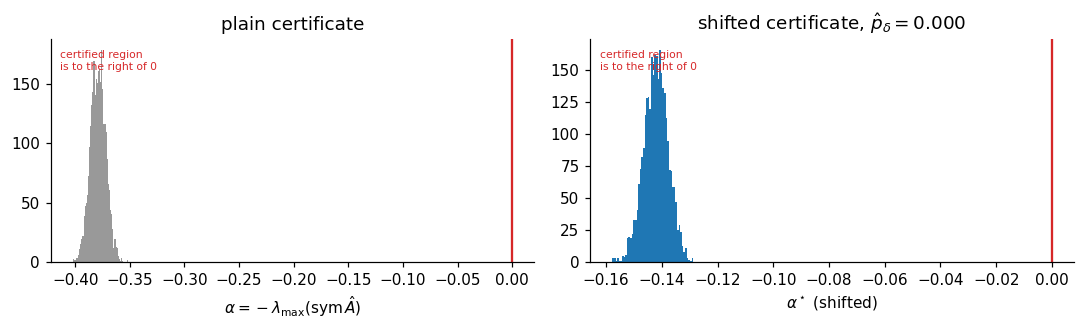

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1))
axes[0].hist(alpha_plain, bins=50, color="0.6"); axes[0].axvline(0, color="C3")
axes[0].set(xlabel=r"$\alpha=-\lambda_{\max}(\mathrm{sym}\,\hat A)$", title="plain certificate")
axes[1].hist(alpha_shift, bins=50, color="C0"); axes[1].axvline(0, color="C3")
axes[1].set(xlabel=r"$\alpha^\star$ (shifted)",
            title=rf"shifted certificate, $\hat p_\delta={p_hat:.3f}$")
for ax in axes:
    ax.text(0.02, 0.95, "certified region\nis to the right of 0", transform=ax.transAxes,
            fontsize=7, va="top", color="C3")
plt.tight_layout(); plt.show()

## 5. Prediction

Problem 1 integrated the *certified* draws, rejection sampling the posterior restricted to
the certified set. Here that set is empty, so the draws are taken from the constrained
posterior as it stands. Each is integrated over the whole domain, including the prediction
window $t\in(15,30]$ that no data came from, and at a parameter value $(a^\star,b^\star)$
that was not in the training set.

Three things are reported: the error against the reference solution, the projection error
of the basis as a floor, and the drift of $E$ along the predicted trajectory --- the last
being the quantity with no dissipation to hide behind.

In [17]:
def compress(Q):   return V.T @ (Q - q_bar[:, None])
def decompress(Qh): return q_bar[:, None] + V @ Qh

def integrate(theta, q0):
    """Solve dq/dt = O d(q) on t_truth.  Returns None if the solver fails."""
    O = theta.reshape(r, dof)
    sol = solve_ivp(lambda t, q: O @ features(q), (0, t_truth[-1]), q0,
                    t_eval=t_truth, method="RK45", rtol=1e-8, atol=1e-10)
    if (not sol.success) or sol.y.shape[1] != t_truth.size:
        return None
    return sol.y

def label(params): return f"({params[0]:g}, {params[1]:g})"

CASES = [(tuple(float(v) for v in TRAIN[l]), TRUTH_TR[l]) for l in range(L)]
CASES.append((tuple(float(v) for v in TEST), TRUTH_TE))

pred_draws = theta_samples[:N_PRED]
t0 = time.time()
ENS = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = [y for y in (integrate(th, q0) for th in pred_draws) if y is not None]
    ENS.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS)} ROM solves in {time.time()-t0:.1f} s")
print("ensemble sizes:", [e.shape[0] for e in ENS])

360 ROM solves in 14.7 s
ensemble sizes: [60, 60, 60, 60, 60, 60]


In [18]:
mask_tr = t_truth <= T_TRAIN      # observation window
mask_pr = t_truth >  T_TRAIN      # prediction window, no data taken there

def errors(Qpred, truth):
    """Relative state error on the two windows separately, as the paper's tables report."""
    e_tr = np.linalg.norm(Qpred[:, mask_tr]-truth[:, mask_tr])/np.linalg.norm(truth[:, mask_tr])
    e_pr = np.linalg.norm(Qpred[:, mask_pr]-truth[:, mask_pr])/np.linalg.norm(truth[:, mask_pr])
    return e_tr, e_pr

def energy(Q):  return 0.5*(Q**2).sum(axis=0)*dx

hdr = f"[0,{T_TRAIN:g}]", f"({T_TRAIN:g},{T_FINAL:g}]"
print(f"{'(a,b)':>14s} | {'constrained':^19s} | {'projection floor':^19s} | {'|dE/E|':>8s}")
print(f"{'':>14s} | {hdr[0]:>9s} {hdr[1]:>9s} | {hdr[0]:>9s} {hdr[1]:>9s} |")
summary = []
for (params, truth), ens in zip(CASES, ENS):
    Qmean = decompress(ens.mean(axis=0))
    Qproj = decompress(compress(truth))
    e_tr, e_pr = errors(Qmean, truth)
    p_tr, p_pr = errors(Qproj, truth)
    E = energy(Qmean); drift = np.abs(E/E[0] - 1).max()
    tag = "  (test)" if params == CASES[-1][0] else ""
    print(f"{label(params):>14s} | {e_tr:9.4f} {e_pr:9.4f} | {p_tr:9.4f} {p_pr:9.4f} | {drift:8.4f}{tag}")
    summary.append((params, e_tr, e_pr, p_tr, p_pr, drift))

         (a,b) |     constrained     |  projection floor   |   |dE/E|
               |    [0,15]   (15,30] |    [0,15]   (15,30] |
    (0.3, 0.8) |    0.0123    0.0349 |    0.0065    0.0071 |   0.0043
    (0.5, 0.8) |    0.0233    0.0752 |    0.0090    0.0107 |   0.0053
    (0.3, 1.2) |    0.0231    0.1288 |    0.0174    0.0204 |   0.0155
    (0.5, 1.2) |    0.0611    0.2418 |    0.0318    0.0338 |   0.0573
      (0.4, 1) |    0.0238    0.1103 |    0.0148    0.0158 |   0.0217
   (0.45, 0.9) |    0.0220    0.1004 |    0.0114    0.0143 |   0.0181  (test)


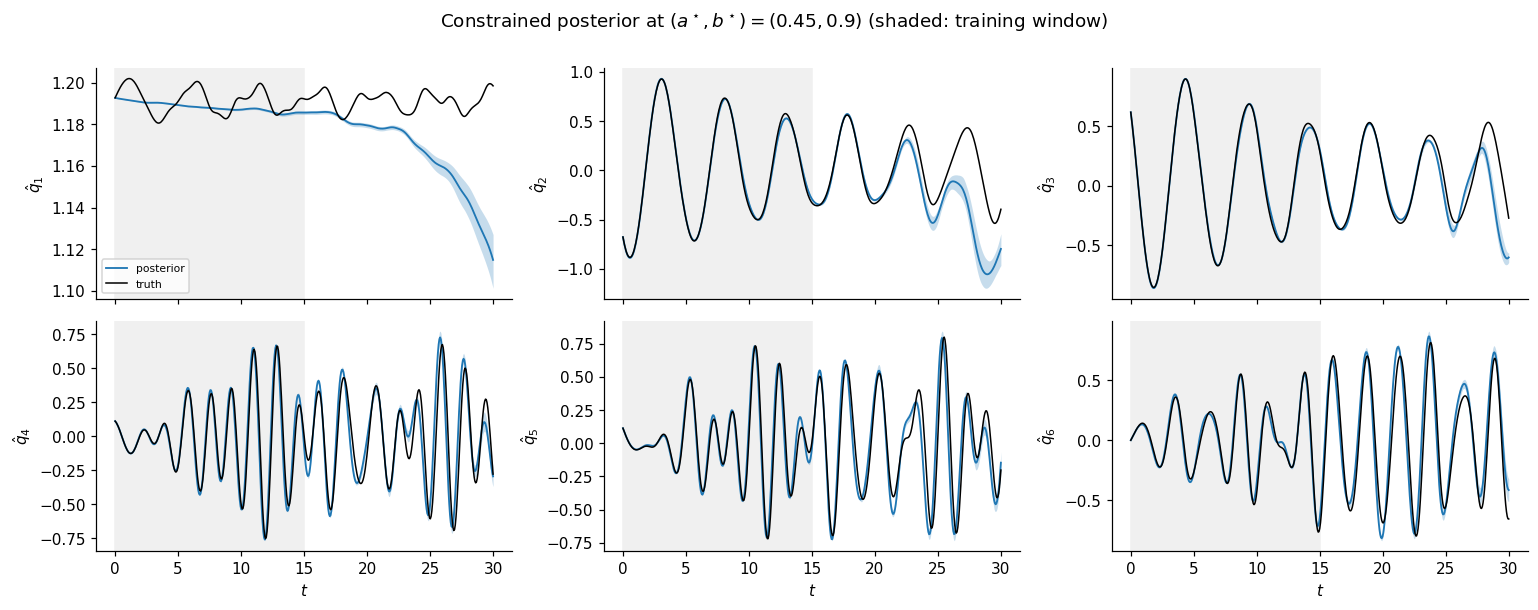

In [19]:
# Reduced coordinates: posterior mean and 95% band against the projected truth.
params, truth = CASES[-1]; ens = ENS[-1]
qh_true = compress(truth)
lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
n_show = 6
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex=True)
for i, ax in enumerate(axes.ravel()[:n_show]):
    ax.fill_between(t_truth, lo_b[i], hi_b[i], color="C0", alpha=0.25, lw=0)
    ax.plot(t_truth, ens.mean(axis=0)[i], "C0", lw=1.2, label="posterior")
    ax.plot(t_truth, qh_true[i], "k", lw=1, label="truth")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    ax.set(ylabel=rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=7)
for ax in axes[-1]: ax.set_xlabel("$t$")
fig.suptitle(rf"Constrained posterior at $(a^\star,b^\star)={params}$ (shaded: training window)", y=1.0)
plt.tight_layout(); plt.show()

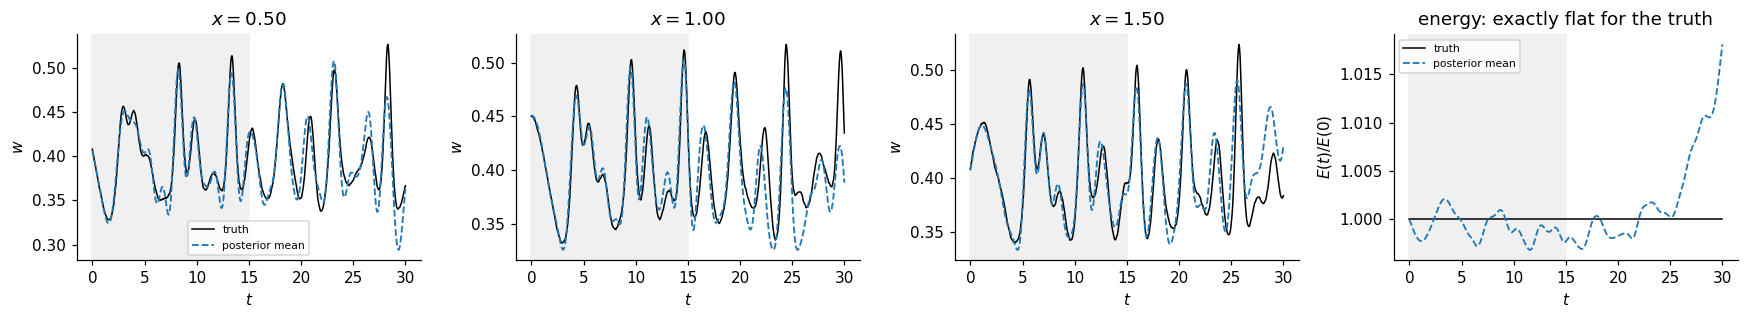

In [20]:
# Physical space at three locations, and the energy of the predicted trajectory.
Qmean = decompress(ens.mean(axis=0))
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, x_loc in zip(axes[:3], (0.5, 1.0, 1.5)):
    i = np.argmin(abs(x - x_loc))
    ax.plot(t_truth, truth[i], "k", lw=1, label="truth")
    ax.plot(t_truth, Qmean[i], "C0--", lw=1.2, label="posterior mean")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    ax.set(xlabel="$t$", ylabel="$w$", title=f"$x={x[i]:.2f}$")
axes[0].legend(fontsize=7)
E_true = energy(truth); E_pred = energy(Qmean)
axes[3].plot(t_truth, E_true/E_true[0], "k", lw=1, label="truth")
axes[3].plot(t_truth, E_pred/E_pred[0], "C0--", lw=1.2, label="posterior mean")
axes[3].axvspan(0, T_TRAIN, color="0.94", zorder=-1)
axes[3].set(xlabel="$t$", ylabel="$E(t)/E(0)$", title="energy: exactly flat for the truth")
axes[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Comparison: the unconstrained posterior

The GP-BayesOpInf baseline, same data and same pipeline with the constraint removed. Its
prior scales are re-selected under its own model, eq. (4) with $\mathbf T=\mathbf I$,
because scales chosen for one model are not the right ones for the other.

This is the comparison problem 2 exists for. Under the constraint a draw can gain energy
only through $\widehat{\mathbf A}$, since $\hat{\mathbf q}^\top\widehat{\mathbf H}(\hat{\mathbf q}\otimes\hat{\mathbf q})$
vanishes identically; the unconstrained posterior has the second route as well. In problem 1
viscosity absorbed whatever $\widehat{\mathbf H}$ produced and hid the difference. Here
nothing does.

In [21]:
# --- prior scales for the unconstrained model: eq. (4) with T = I ---
Phi_W_Phi = Phi.T @ (wvec[:, None]*Phi)
Phi_W_z   = Phi.T @ (wvec*zvec)

def log_evidence_unc(gam):
    gamma_sq = prior_scales(gam)**2
    P0 = np.diag(gamma_sq)                       # T = I, so P0 is simply diag(gamma^2)
    P  = Phi_W_Phi + P0
    sign0, logdet_P0 = np.linalg.slogdet(P0)
    signP, logdet_P  = np.linalg.slogdet(P)
    if sign0 <= 0 or signP <= 0:
        return -1e12
    mu_u = solve(P, Phi_W_z, assume_a="pos")
    return (-0.5*Nobs*np.log(2*np.pi) + 0.5*logdet_W + 0.5*logdet_P0 - 0.5*logdet_P
            - 0.5*(z_W_z - mu_u @ (P @ mu_u)))

t0 = time.time(); best_u = None
for log_gamma_0 in ([-2.]*3, [0.]*3, [2.]*3):
    res = minimize(lambda lg: -log_evidence_unc(np.exp(lg)), log_gamma_0,
                   method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best_u is None or res.fun < best_u.fun:
        best_u = res
gamma_u = np.exp(best_u.x)
print(f"unconstrained evidence {-best_u.fun:.2f} in {time.time()-t0:.1f} s")
print(f"   gamma = {np.array2string(gamma_u, precision=4)}   "
      f"(constrained: {np.array2string(gamma, precision=4)})")

unconstrained evidence -52087.75 in 7.5 s
   gamma = [37.5195  1.379   7.129 ]   (constrained: [37.1665  1.3715  7.3371])


In [22]:
# --- row posteriors and draws of the unconstrained model, no correction applied ---
gvec_u = prior_scales(gamma_u)
mu_u = np.zeros(n); Lchol_u = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec_u[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    mu_u[block] = Sig_i @ DWz[i]
    Lchol_u.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))

def draw_unc(rng):
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu_u[block] + Lchol_u[i] @ rng.standard_normal(dof)
    return theta

rng = np.random.default_rng(SEED)
theta_u = np.array([draw_unc(rng) for _ in range(N_PRED)])

# How far from energy preserving the baseline is, in the quadratic form itself.
def ep_residual(theta):
    H = expand_H(unpack(theta)[2])
    rng_q = np.random.default_rng(0)
    qs = rng_q.standard_normal((100, r))
    scale = np.mean([np.linalg.norm(q)**3 for q in qs])
    return np.mean([abs(q @ (H @ np.kron(q, q))) for q in qs])/scale

print(f"\nrelative |q' H (q x q)| :  constrained {ep_residual(mu_c):.3e}, "
      f"unconstrained {ep_residual(mu_u):.3e}")


relative |q' H (q x q)| :  constrained 4.155e-17, unconstrained 9.070e-02


In [23]:
# --- the same N_PRED draws integrated over the same cases ---
t0 = time.time()
ENS_U = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = [y for y in (integrate(th, q0) for th in theta_u) if y is not None]
    ENS_U.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS_U)} baseline solves in {time.time()-t0:.1f} s")
print(f"{'(a,b)':>14s} {'constrained':>13s} {'unconstrained':>15s}   (draws reaching "
      f"t = 30, of {N_PRED})")
for (params, _), ec, eu in zip(CASES, ENS, ENS_U):
    print(f"{label(params):>14s} {ec.shape[0]:13d} {eu.shape[0]:15d}")

102 baseline solves in 14.3 s
         (a,b)   constrained   unconstrained   (draws reaching t = 30, of 60)
    (0.3, 0.8)            60              60
    (0.5, 0.8)            60               0
    (0.3, 1.2)            60               0
    (0.5, 1.2)            60              13
      (0.4, 1)            60              15
   (0.45, 0.9)            60              14


In [24]:
# Side by side.  Errors are computed over the draws that survived in each posterior,
# so a baseline that diverges more often is also reported as surviving less often.
# Same two windows as the table above: observed, then predicted.
print(f"{'(a,b)':>14s} | {'constrained':^23s} | {'unconstrained':^23s}")
print(f"{'':>14s} | {hdr[0]:>10s} {hdr[1]:>10s} | {hdr[0]:>10s} {hdr[1]:>10s}")
rows_tab = []
for (params, truth), ens_c, ens_u in zip(CASES, ENS, ENS_U):
    e1c, e2c = errors(decompress(ens_c.mean(axis=0)), truth) if ens_c.size else (np.nan, np.nan)
    e1u, e2u = errors(decompress(ens_u.mean(axis=0)), truth) if ens_u.size else (np.nan, np.nan)
    print(f"{label(params):>14s} | {e1c:10.4f} {e2c:10.4f} | {e1u:10.4f} {e2u:10.4f}")
    rows_tab.append((params, e1c, e2c, e1u, e2u))

# Energy drift of the two posteriors, the quantity nothing damps in this problem.
print(f"\n{'(a,b)':>14s} {'|dE/E| constrained':>20s} {'|dE/E| unconstrained':>22s}")
drift_tab = []
def max_drift(ens):
    # nan when every draw of that posterior diverged before reaching t = 30
    if ens.size == 0:
        return np.nan
    E = energy(decompress(ens.mean(axis=0)))
    return np.abs(E/E[0] - 1).max()

for (params, truth), ens_c, ens_u in zip(CASES, ENS, ENS_U):
    dc, du = max_drift(ens_c), max_drift(ens_u)
    print(f"{label(params):>14s} {dc:20.4f} {du:22.4f}")
    drift_tab.append((params, dc, du))

         (a,b) |       constrained       |      unconstrained     
               |     [0,15]    (15,30] |     [0,15]    (15,30]
    (0.3, 0.8) |     0.0123     0.0349 |     0.0112     0.0388
    (0.5, 0.8) |     0.0233     0.0752 |        nan        nan
    (0.3, 1.2) |     0.0231     0.1288 |        nan        nan
    (0.5, 1.2) |     0.0611     0.2418 |     0.3888     0.4529
      (0.4, 1) |     0.0238     0.1103 |     0.1091     0.3899
   (0.45, 0.9) |     0.0220     0.1004 |     0.1847     0.4593

         (a,b)   |dE/E| constrained   |dE/E| unconstrained
    (0.3, 0.8)               0.0043                 0.0057
    (0.5, 0.8)               0.0053                    nan
    (0.3, 1.2)               0.0155                    nan
    (0.5, 1.2)               0.0573                 0.1932
      (0.4, 1)               0.0217                 0.1348
   (0.45, 0.9)               0.0181                 0.1754


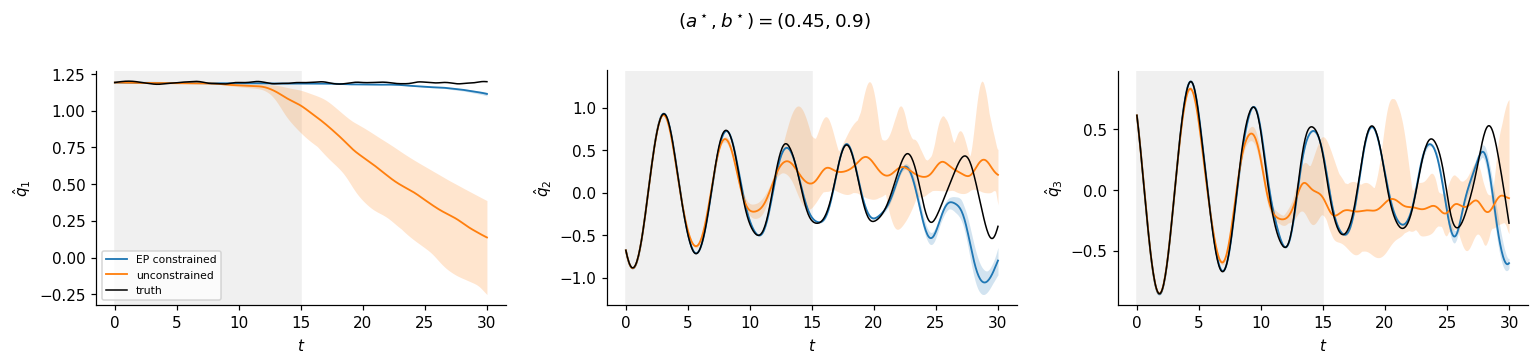

In [25]:
# The two posteriors on the held-out trajectory, in the three leading coordinates.
params, truth = CASES[-1]
qh_true = compress(truth)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharex=True)
for i, ax in enumerate(axes):
    for ens, color, name in ((ENS[-1], "C0", "EP constrained"), (ENS_U[-1], "C1", "unconstrained")):
        if ens.size == 0: continue        # that posterior had no surviving draw
        lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
        ax.fill_between(t_truth, lo_b[i], hi_b[i], color=color, alpha=0.2, lw=0)
        ax.plot(t_truth, ens.mean(axis=0)[i], color=color, lw=1.2, label=name)
    ax.plot(t_truth, qh_true[i], "k", lw=1, label="truth")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    ax.set(xlabel="$t$", ylabel=rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=7)
fig.suptitle(rf"$(a^\star,b^\star)={params}$", y=1.02)
plt.tight_layout(); plt.show()

## 7. Constraining the linear part as well

Energy preservation is a condition on $\widehat{\mathbf H}$ alone, and \S4 showed what it
leaves open: the quadratic term moves no energy, so every unit of growth enters through
$\widehat{\mathbf A}$, and $\alpha=-\lambda_{\max}(\mathrm{sym}\,\widehat{\mathbf A})$ is
about $-1.1$ for every draw. The semidiscrete operator has no symmetric part at all
($\mathrm{sym}\,\mathbf A_F=\mathbf 0$, section 2 of the data notebook), so it is natural
to ask for the same of the inferred one:

$$
\mathrm{sym}\,\widehat{\mathbf A}=\mathbf 0
\quad\Longleftrightarrow\quad
\hat A_{ii}=0,\qquad \hat A_{ij}+\hat A_{ji}=0\ \ (i<j),
$$

which is $r(r+1)/2$ further linear equalities in $\boldsymbol\theta$. They are appended as
extra rows of $\mathbf C$, and nothing else in the method changes: the Kalman update, the
Matheron correction and the closed forms all act through $\mathbf C$ and are indifferent to
which rows it has. Two properties carry over as well, and the cell below checks both: the
rows stay independent, and $\mathbf C\mathbf C^\top$ stays diagonal, since each new row
touches entries of $\widehat{\mathbf A}$ that no other row touches.

What it buys is a bound that holds for every draw, with no certificate and no sampling. With
$\mathrm{sym}\,\widehat{\mathbf A}=\mathbf 0$ and $\widehat{\mathbf H}$ energy preserving,
the energy balance collapses to its constant term,

$$
\dot V=\hat{\mathbf q}^\top\hat{\mathbf c},
\qquad\text{so}\qquad
\|\hat{\mathbf q}(t)\|\le\|\hat{\mathbf q}(0)\|+\|\hat{\mathbf c}\|\,t ,
$$

at most linear growth, against the $e^{1.1t}$ the previous sections could not rule out.

What it costs is the certificate. For any shift $\mathbf m$, energy preservation makes the
cubic term vanish at $\hat{\mathbf q}=\mathbf m$ itself, so

$$
\mathbf m^\top\mathrm{sym}(\widehat{\mathbf A}+\mathbf L_{\mathbf m})\,\mathbf m
=\mathbf m^\top\mathrm{sym}(\widehat{\mathbf A})\,\mathbf m
+2\,\mathbf m^\top\widehat{\mathbf H}(\mathbf m\otimes\mathbf m)
=\mathbf m^\top\mathrm{sym}(\widehat{\mathbf A})\,\mathbf m ,
$$

and therefore
$\lambda_{\max}(\mathrm{sym}(\widehat{\mathbf A}+\mathbf L_{\mathbf m}))\ge
\mathbf m^\top\mathrm{sym}(\widehat{\mathbf A})\mathbf m/\|\mathbf m\|^2$. A certifying shift
must point along a dissipative direction of $\widehat{\mathbf A}$; with
$\mathrm{sym}\,\widehat{\mathbf A}=\mathbf 0$ there is none, so $\alpha=\alpha^\star=0$
exactly and no trapping region exists. The two guarantees are alternatives, not
complements, and the last cell checks the identity numerically.

In [26]:
# --- the skew-symmetry rows, appended to C ---
def index_of_a(i, j):
    """Where the coefficient A_ij sits inside theta: row i starts at i*dof with c_i."""
    return i*dof + 1 + j

rows_A = []
for i in range(r):                                   # the diagonal vanishes
    row = np.zeros(n); row[index_of_a(i, i)] = 1.0; rows_A.append(row)
for i in range(r):                                   # and each off-diagonal pair sums to 0
    for j in range(i+1, r):
        row = np.zeros(n)
        row[index_of_a(i, j)] = 1.0; row[index_of_a(j, i)] = 1.0
        rows_A.append(row)
Cmat_A  = np.array(rows_A)
Cmat_HA = np.vstack([Cmat, Cmat_A])                  # Cmat is the energy-preserving block
Tker_HA = null_space(Cmat_HA)

n_a = r*(r+1)//2
print(f"C_A  {Cmat_A.shape},  expected {n_a} rows,  rank {np.linalg.matrix_rank(Cmat_A)}")
print(f"C_HA {Cmat_HA.shape},  rank {np.linalg.matrix_rank(Cmat_HA)} "
      f"(expected {n_c} + {n_a} = {n_c + n_a})")
print(f"ker C_HA: {Tker_HA.shape},  ||C_HA T|| = {np.abs(Cmat_HA @ Tker_HA).max():.2e}")

# The property section 3.2 relies on: orthogonal rows, so orthonormalising them is a
# rescaling rather than a factorisation.
gram = Cmat_HA @ Cmat_HA.T
off = np.abs(gram - np.diag(np.diag(gram))).max()
print(f"C_HA C_HA' diagonal: max off-diagonal {off:.1e}, "
      f"diagonal entries {sorted(set(np.diag(gram).astype(int)))}")


C_A  (55, 660),  expected 55 rows,  rank 55
C_HA (275, 660),  rank 275 (expected 220 + 55 = 275)
ker C_HA: (660, 385),  ||C_HA T|| = 4.44e-16
C_HA C_HA' diagonal: max off-diagonal 0.0e+00, diagonal entries [np.int64(1), np.int64(2), np.int64(3)]


In [27]:
# --- the H-and-A posterior: section 3.2 and 3.3 again, with the larger C ---
# The evidence of eq. (4) in the coordinates of ker C_HA.  Same expression as the
# log_evidence above; written out again because the basis it is applied to changed.
PhiT_HA        = Phi @ Tker_HA
PhiT_W_PhiT_HA = PhiT_HA.T @ (wvec[:, None]*PhiT_HA)
PhiT_W_z_HA    = PhiT_HA.T @ (wvec*zvec)
M_block_HA     = [Tker_HA[block_of == b].T @ Tker_HA[block_of == b] for b in (0, 1, 2)]

def log_evidence_HA(gam):
    P0 = sum((gam[b]**2)*M_block_HA[b] for b in range(3))
    P  = PhiT_W_PhiT_HA + P0
    sign0, logdet_P0 = np.linalg.slogdet(P0)
    signP, logdet_P  = np.linalg.slogdet(P)
    if sign0 <= 0 or signP <= 0:
        return -1e12
    mu_z = solve(P, PhiT_W_z_HA, assume_a="pos")
    return (-0.5*Nobs*np.log(2*np.pi) + 0.5*logdet_W + 0.5*logdet_P0 - 0.5*logdet_P
            - 0.5*(z_W_z - mu_z @ (P @ mu_z)))

t0 = time.time(); best_HA = None
for log_gamma_0 in ([-2.]*3, [0.]*3, [2.]*3):
    res = minimize(lambda lg: -log_evidence_HA(np.exp(lg)), log_gamma_0,
                   method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-3, maxfev=2000))
    if best_HA is None or res.fun < best_HA.fun:
        best_HA = res
gamma_HA = np.exp(best_HA.x)
print(f"evidence maximised in {time.time()-t0:.1f} s,  log p(z~) = {-best_HA.fun:.2f}")
print(f"   gamma = {np.array2string(gamma_HA, precision=4)}   "
      f"(H only: {np.array2string(gamma, precision=4)})")

# Row posteriors, then the single Kalman update of eq. (5) with C_HA in place of C.
gvec_HA = prior_scales(gamma_HA)
Sig_HA = np.zeros((n, n)); mu_HA_unc = np.zeros(n); Lchol_HA = []
for i in range(r):
    block = slice(i*dof, (i+1)*dof)
    Sig_i = np.linalg.inv(DWD[i] + np.diag(gvec_HA[block]**2))
    Sig_i = 0.5*(Sig_i + Sig_i.T)
    Sig_HA[block, block] = Sig_i
    mu_HA_unc[block] = Sig_i @ DWz[i]
    Lchol_HA.append(cholesky(Sig_i + 1e-14*np.eye(dof), lower=True))

Sig_Ct_HA = Sig_HA @ Cmat_HA.T
Kg_HA     = solve(Cmat_HA @ Sig_Ct_HA, Sig_Ct_HA.T, assume_a="pos").T
mu_HA     = mu_HA_unc - Kg_HA @ (Cmat_HA @ mu_HA_unc)

def draw_HA(rng):
    theta = np.zeros(n)
    for i in range(r):
        block = slice(i*dof, (i+1)*dof)
        theta[block] = mu_HA[block] + Lchol_HA[i] @ rng.standard_normal(dof)
    return theta - Kg_HA @ (Cmat_HA @ theta)      # the same linear correction

rng = np.random.default_rng(SEED)
theta_HA = np.array([draw_HA(rng) for _ in range(N_PRED)])

c_HA, A_HA, H_HA_compact = unpack(mu_HA)
print(f"\n||C_HA mu_HA||  = {np.linalg.norm(Cmat_HA @ mu_HA):.3e}")
print(f"||C_HA theta||   = {np.abs(Cmat_HA @ theta_HA.T).max():.3e}   (draw by draw)")
print(f"||sym A_hat||_F  = {np.linalg.norm(0.5*(A_HA + A_HA.T)):.3e}   "
      f"(H only: {np.linalg.norm(0.5*(unpack(mu_c)[1] + unpack(mu_c)[1].T)):.3e})")
print(f"||c_hat||        = {np.linalg.norm(c_HA):.4f}   -> the growth bound is "
      f"||q(0)|| + {np.linalg.norm(c_HA):.3f} t")

# The certificate, for the record: alpha and alpha* are zero by the argument above.
a_HA, a_star_HA, m_HA, _, _ = certify(mu_HA)
print(f"\ncertificate of the mean: alpha = {a_HA:+.2e}, alpha* = {a_star_HA:+.2e}"
      "   (both zero: sym A_hat = 0 and the shift cannot help)")


evidence maximised in 1.7 s,  log p(z~) = -77556.64
   gamma = [50.7535  0.9262  7.394 ]   (H only: [37.1665  1.3715  7.3371])

||C_HA mu_HA||  = 2.405e-15
||C_HA theta||   = 4.441e-16   (draw by draw)
||sym A_hat||_F  = 5.045e-16   (H only: 4.933e-01)
||c_hat||        = 0.0623   -> the growth bound is ||q(0)|| + 0.062 t

certificate of the mean: alpha = -2.69e-16, alpha* = -6.85e-10   (both zero: sym A_hat = 0 and the shift cannot help)


In [28]:
# --- the same 60 draws integrated over the same six cases ---
t0 = time.time()
ENS_HA = []
for params, truth in CASES:
    q0 = compress(truth[:, :1]).ravel()
    runs = [y for y in (integrate(th, q0) for th in theta_HA) if y is not None]
    ENS_HA.append(np.array(runs))
print(f"{sum(e.shape[0] for e in ENS_HA)} ROM solves in {time.time()-t0:.1f} s")

# Three posteriors side by side: the baseline of section 6, the energy-preserving one,
# and the one that also has a skew linear part.
print(f"\n{'(a,b)':>13s} {'draws reaching t = 30, of ' + str(N_PRED):>34s}")
print(f"{'':>13s} {'unconstrained':>15s} {'H':>9s} {'H and A':>9s}")
for (params, _), eu, ec, eh in zip(CASES, ENS_U, ENS, ENS_HA):
    print(f"{label(params):>13s} {eu.shape[0]:15d} {ec.shape[0]:9d} {eh.shape[0]:9d}")

print(f"\n{'(a,b)':>13s} | {'H: error':^19s} | {'H and A: error':^19s}")
print(f"{'':>13s} | {hdr[0]:>9s} {hdr[1]:>9s} | {hdr[0]:>9s} {hdr[1]:>9s}")
rows_HA = []
for (params, truth), ec, eh in zip(CASES, ENS, ENS_HA):
    e1c, e2c = errors(decompress(ec.mean(axis=0)), truth)
    e1h, e2h = errors(decompress(eh.mean(axis=0)), truth)
    print(f"{label(params):>13s} | {e1c:9.4f} {e2c:9.4f} | {e1h:9.4f} {e2h:9.4f}")
    rows_HA.append((params, e1c, e2c, e1h, e2h))
print(f"{'mean':>13s} | {np.mean([r[1] for r in rows_HA]):9.4f} "
      f"{np.mean([r[2] for r in rows_HA]):9.4f} | "
      f"{np.mean([r[3] for r in rows_HA]):9.4f} {np.mean([r[4] for r in rows_HA]):9.4f}")


360 ROM solves in 14.7 s

        (a,b)       draws reaching t = 30, of 60
                unconstrained         H   H and A
   (0.3, 0.8)              60        60        60
   (0.5, 0.8)               0        60        60
   (0.3, 1.2)               0        60        60
   (0.5, 1.2)              13        60        60
     (0.4, 1)              15        60        60
  (0.45, 0.9)              14        60        60

        (a,b) |      H: error       |   H and A: error   
              |    [0,15]   (15,30] |    [0,15]   (15,30]
   (0.3, 0.8) |    0.0123    0.0349 |    0.0111    0.0285
   (0.5, 0.8) |    0.0233    0.0752 |    0.0220    0.0592
   (0.3, 1.2) |    0.0231    0.1288 |    0.0226    0.0669
   (0.5, 1.2) |    0.0611    0.2418 |    0.0606    0.1248
     (0.4, 1) |    0.0238    0.1103 |    0.0235    0.0450
  (0.45, 0.9) |    0.0220    0.1004 |    0.0214    0.0489
         mean |    0.0276    0.1152 |    0.0269    0.0622


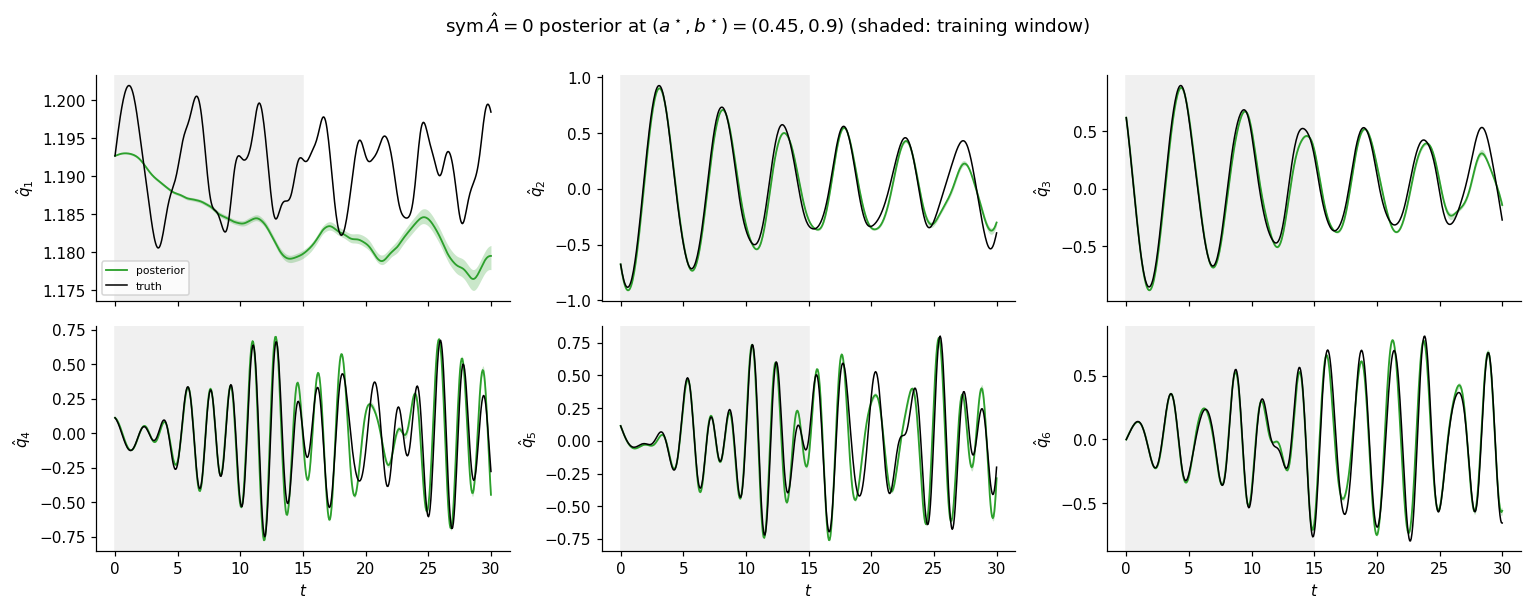

In [29]:
# Reduced coordinates of the H-and-A posterior: mean and 95% band against the truth.
params, truth = CASES[-1]; ens = ENS_HA[-1]
qh_true = compress(truth)
lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
n_show = 6
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex=True)
for i, ax in enumerate(axes.ravel()[:n_show]):
    ax.fill_between(t_truth, lo_b[i], hi_b[i], color="C2", alpha=0.25, lw=0)
    ax.plot(t_truth, ens.mean(axis=0)[i], "C2", lw=1.2, label="posterior")
    ax.plot(t_truth, qh_true[i], "k", lw=1, label="truth")
    ax.axvspan(0, T_TRAIN, color="0.94", zorder=-1)
    ax.set(ylabel=rf"$\hat q_{{{i+1}}}$")
    if i == 0: ax.legend(fontsize=7)
for ax in axes[-1]: ax.set_xlabel("$t$")
fig.suptitle(rf"$\mathrm{{sym}}\,\hat A=0$ posterior at $(a^\star,b^\star)={params}$ "
             "(shaded: training window)", y=1.0)
plt.tight_layout(); plt.show()


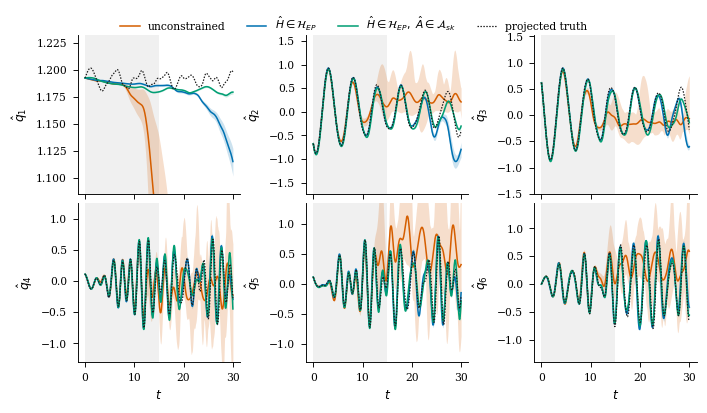

   H only: mean 95% width on (15,30], coordinates 1-6   0.006  0.121  0.072  0.071  0.074  0.086
  H and A: mean 95% width on (15,30], coordinates 1-6   0.002  0.039  0.036  0.043  0.044  0.048


In [30]:
import matplotlib as mpl

PAPER_RC = {
    "font.family": "serif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "lines.linewidth": 1.0, "pdf.fonttype": 42,
}
C_CON, C_UNC, C_SKEW = "#0072B2", "#D55E00", "#009E73"

params, truth = CASES[-1]
qh_true = compress(truth)
SERIES = ((ENS_U[-1],  C_UNC,  "unconstrained"),
          (ENS[-1],    C_CON,  r"$\hat H\in\mathcal{H}_{EP}$"),
          (ENS_HA[-1], C_SKEW, r"$\hat H\in\mathcal{H}_{EP},\ \hat A\in\mathcal{A}_{sk}$"))

with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(2, 3, figsize=(6.3, 3.4), sharex=True)
    for i, ax in enumerate(axes.ravel()[:6]):
        for ens, color, name in SERIES:
            if ens.size == 0:
                continue
            lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
            ax.fill_between(t_truth, lo_b[i], hi_b[i], color=color, alpha=0.2, lw=0)
            ax.plot(t_truth, ens.mean(axis=0)[i], color=color, label=name)
        ax.plot(t_truth, qh_true[i], color="0.1", ls=(0, (1.2, 1.2)), lw=0.8,
                label="projected truth")
        ax.axvspan(0, T_TRAIN, color="0.94", lw=0, zorder=-2)
        # The axes are set from the truth and the two constrained posteriors; the
        # unconstrained mean leaves them where it diverges.
        span = np.concatenate([qh_true[i], ENS[-1].mean(axis=0)[i],
                               ENS_HA[-1].mean(axis=0)[i]])
        pad = 0.35*(span.max() - span.min() + 1e-12)
        ax.set_ylim(span.min() - pad, span.max() + pad)
        ax.set_ylabel(rf"$\hat q_{{{i+1}}}$")
    for ax in axes[-1]:
        ax.set_xlabel("$t$")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
               handlelength=1.8, bbox_to_anchor=(0.5, 1.07))
    fig.tight_layout(pad=0.3)
    fig.savefig("fig_prob2_comparison.pdf", bbox_inches="tight")
    plt.show()

# And the band widths, since the two constrained posteriors look similar by eye: the
# mean width of the 95 % interval over the prediction window, per coordinate.
for ens, name in ((ENS[-1], "H only"), (ENS_HA[-1], "H and A")):
    lo_b, hi_b = np.percentile(ens, [2.5, 97.5], axis=0)
    w = (hi_b - lo_b)[:, t_truth > T_TRAIN].mean(axis=1)
    print(f"{name:>9s}: mean 95% width on (15,30], coordinates 1-6  "
          + " ".join(f"{v:6.3f}" for v in w[:6]))

In [31]:
# --- what the constraint was imposed for: growth, draw by draw ---
# V = ||q_hat||^2 / 2 is the quantity the constraints act on, so it is read per draw.
# Averaging first would hide the growth: draws dephase, and the mean of 60 of them has
# a smaller norm than any of them.
def growth_report(ens, c_vec):
    """Median and worst relative change of V, worst growth of ||q_hat||, and how many
    draws obey ||q(t)|| <= ||q(0)|| + ||c|| t."""
    dV, grow, held = [], [], 0
    for y in ens:
        Vt = 0.5*(y**2).sum(axis=0)
        dV.append(np.abs(Vt/Vt[0] - 1).max())
        nq = np.linalg.norm(y, axis=0)
        grow.append(nq.max()/nq[0])
        held += bool(np.all(nq <= nq[0] + np.linalg.norm(c_vec)*t_truth + 1e-8))
    return np.median(dV), np.max(dV), np.max(grow), held

c_H = unpack(mu_c)[0]
print(f"{'(a,b)':>13s} | {'H: |dV/V| med':>13s} {'max':>8s} {'growth':>7s} {'bound':>7s} "
      f"| {'H+A: |dV/V| med':>15s} {'max':>8s} {'growth':>7s} {'bound':>7s}")
for (params, _), ec, eh in zip(CASES, ENS, ENS_HA):
    mc, xc, gc, hc = growth_report(ec, c_H)
    mh, xh, gh, hh = growth_report(eh, c_HA)
    print(f"{label(params):>13s} | {mc:13.3f} {xc:8.3f} {gc:7.2f} "
          f"{str(hc)+'/'+str(len(ec)):>7s} | {mh:15.3f} {xh:8.3f} {gh:7.2f} "
          f"{str(hh)+'/'+str(len(eh)):>7s}")
print("\n-> with sym A_hat = 0 the reduced energy moves by tens of percent instead of"
      "\n   factors of ten, no draw grows by more than a few percent, and every draw obeys"
      "\n   the linear bound at every parameter value.")


        (a,b) | H: |dV/V| med      max  growth   bound | H+A: |dV/V| med      max  growth   bound
   (0.3, 0.8) |         0.069    0.083    1.04   60/60 |           0.017    0.017    1.01   60/60
   (0.5, 0.8) |         0.201    0.309    1.14   60/60 |           0.011    0.012    1.00   60/60
   (0.3, 1.2) |         0.161    0.283    1.13   60/60 |           0.014    0.014    1.01   60/60
   (0.5, 1.2) |         2.188    5.047    2.46   59/60 |           0.031    0.035    1.01   60/60
     (0.4, 1) |         2.612    4.729    2.39   60/60 |           0.067    0.069    1.02   60/60
  (0.45, 0.9) |         1.188    1.933    1.71   60/60 |           0.028    0.031    1.01   60/60

-> with sym A_hat = 0 the reduced energy moves by tens of percent instead of
   factors of ten, no draw grows by more than a few percent, and every draw obeys
   the linear bound at every parameter value.


In [32]:
# --- the identity behind "no trapping region", checked on the two posteriors ---
# m' sym(A + L_m) m = m' sym(A) m  for every m, because q' H (q (x) q) = 0 at q = m.
# With A skew the right-hand side is 0, so lambda_max >= 0 and alpha_m <= 0 always.
rng_id = np.random.default_rng(1)
for tag, theta in (("H only", mu_c), ("H and A", mu_HA)):
    _, A_t, H_t = unpack(theta)
    H_full = expand_H(H_t); sym_A_t = 0.5*(A_t + A_t.T)
    worst, worst_form = 0.0, 0.0
    for _ in range(200):
        m = rng_id.standard_normal(r)
        Lm = L_of_m(H_full, m)
        lhs = m @ (sym_A_t + 0.5*(Lm + Lm.T)) @ m
        rhs = m @ sym_A_t @ m
        worst = max(worst, abs(lhs - rhs))
        worst_form = max(worst_form, abs(rhs)/(m @ m))
    print(f"{tag:>9s}:  max |m'sym(A+L_m)m - m'sym(A)m| = {worst:.2e},   "
          f"max |m'sym(A)m|/||m||^2 = {worst_form:.3e}")
print("\n-> the shift never changes the quadratic form in its own direction.  For the"
      "\n   skew model that form is zero, so no shift can make sym(A + L_m) negative"
      "\n   definite: alpha* = 0 is the best the SDP can return, as it did above.")


   H only:  max |m'sym(A+L_m)m - m'sym(A)m| = 2.78e-14,   max |m'sym(A)m|/||m||^2 = 2.442e-01
  H and A:  max |m'sym(A+L_m)m - m'sym(A)m| = 3.31e-14,   max |m'sym(A)m|/||m||^2 = 1.999e-16

-> the shift never changes the quadratic form in its own direction.  For the
   skew model that form is zero, so no shift can make sym(A + L_m) negative
   definite: alpha* = 0 is the best the SDP can return, as it did above.


## 8. Save

In [33]:
# Per-case ensemble summaries in reduced coordinates, so the paper figures can be
# redrawn without re-integrating anything.
def summarize(ens):
    if ens.size == 0:
        return np.full((3, r, t_truth.size), np.nan)
    return np.stack([ens.mean(axis=0),
                     np.percentile(ens, 2.5, axis=0),
                     np.percentile(ens, 97.5, axis=0)])

np.savez_compressed(
    "results_KdV1D.npz",
    r=r, seed=SEED, n_samp=N_SAMP, n_pred=N_PRED, delta=DELTA,
    gamma=gamma, gamma_unc=gamma_u, gamma_skewA=gamma_HA,
    theta_mean=mu_c, theta_mean_unc=mu_u, theta_mean_skewA=mu_HA,
    alpha=alpha_plain, alpha_star=alpha_shift, p_hat=p_hat, cp_interval=np.array([lo, hi]),
    centre=centre, n_positive=n_positive,
    case_params=np.array([p for p, _ in CASES]),
    ens_summary=np.stack([summarize(e) for e in ENS]),
    ens_summary_unc=np.stack([summarize(e) for e in ENS_U]),
    ens_summary_skewA=np.stack([summarize(e) for e in ENS_HA]),
    errors_skewA=np.array([[e1h, e2h] for _, _, _, e1h, e2h in rows_HA]),
    errors=np.array([[e1c, e2c, e1u, e2u] for _, e1c, e2c, e1u, e2u in rows_tab]),
    drift=np.array([[dc, du] for _, dc, du in drift_tab]),
    deriv_rel_err=rel_err, deriv_abs_err=abs_err,
    deriv_rms=deriv_rms,
)
import os
print(f"saved results_KdV1D.npz  ({os.path.getsize('results_KdV1D.npz')/2**20:.1f} MiB)")

saved results_KdV1D.npz  (2.0 MiB)
